# Tome 15, Appendix B: Twin primes and prime gaps (Python companion)

Exercises first, solutions at the end. We test admissible sets, count twin primes, cousins and prime triples up to $10^8$ against the Hardy–Littlewood predictions, chase the record gaps, look at the shape of the gap distribution, and rebuild Jacobsthal's runs from the proof of Westzynthius's theorem. We use `numpy`, `sympy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, itertools
import numpy as np
import sympy
from sympy.ntheory.modular import crt
import matplotlib.pyplot as plt
N = 10**8
s = np.ones(N + 250, bool); s[:2] = False; s[4::2] = False
for p in range(3, int((N + 250)**0.5) + 1, 2):
    if s[p]: s[p*p::2*p] = False
P = np.nonzero(s[:N + 1])[0]
print(len(P), 'primes up to 10^8')

5761455 primes up to 10^8


## Exercises

**P2.1 (★) Admissible sets.** Write a function that decides whether a set $\mathcal H$ of integers is admissible. Find, for $k=2,\dots,6$, the smallest diameter of an admissible $k$-tuple $\{0<h_2<\dots<h_k\}$. Then check Proposition 2.1: the $k$ primes after $\pi(k)$ form an admissible set, and compare its diameter with $k\log k$ (Exercise 2.5).

**P2.2 (★★) Hardy and Littlewood against the data.** Count the prime pairs $(p,p+2)$, $(p,p+4)$ and the triples $(p,p+2,p+6)$ up to $x=10^4,10^5,\dots,10^8$, and compare with $\mathfrak S(\mathcal H)\int_2^x\frac{dt}{(\log t)^k}$. Check also the upper bound shape of Proposition 2.2: the ratio of $\pi_2(x)$ to $x/(\log x)^2$.

**P2.3 (★★) Gaps.** List the record gaps $d_n=p_{n+1}-p_n$ below $10^8$ and compare them with $(\log p_n)^2$. Plot the histogram of the normalised gaps $d_n/\log p_n$ for $p_n\in[10^7,10^8]$ against the exponential density $e^{-t}$. What fraction of gaps is below $\delta\log p_n$ for $\delta=\frac14$ (Theorem 2.4)?

**P2.4 (★) Singular series on average.** For even $h$, the pair $(0,h)$ has $\mathfrak S(h)=2C_2\prod_{p\mid h,\,p>2}\frac{p-1}{p-2}$, and $\mathfrak S(h)=0$ for odd $h$. Compute $\frac1H\sum_{h\le H}\mathfrak S(h)$ for $H=10^2,\dots,10^6$, and compare the count of $p\le10^8$ with $p+h$ prime against $\mathfrak S(h)\int_2^x\frac{dt}{\log^2t}$ for $h=2,6,30,210$. Check also Exercise 2.6.

**P2.5 (★★) Jacobsthal's runs.** For each primorial $m=6,30,210,2310,30030$, find the longest run of consecutive integers sharing a factor with $m$ (Exercise 2.8). Then carry out the construction of Theorem 2.5 for $x=30$: choose classes by the Chinese remainder theorem and exhibit an explicit run of composites.

## Solutions

### P2.1
**How to find it.** A set is admissible when, for each prime $p\le k$, it misses some residue class modulo $p$; primes $p>k$ cannot be covered by $k$ elements. For the minimal diameters, search all $k$-subsets of $\{0,\dots,D\}$ containing $0$ and $D$, for increasing $D$.

In [2]:
def admissible(H):
    k = len(H)
    return all(len({h % p for h in H}) < p for p in sympy.primerange(2, k + 1))

for k in range(2, 7):
    D = k - 1
    while True:
        found = [(0,) + c + (D,) for c in itertools.combinations(range(1, D), k - 2)
                 if admissible((0,) + c + (D,))]
        if found:
            print(k, 'minimal diameter', D, 'e.g.', found[:2]); break
        D += 1
for k in (10, 100, 1000, 10000):
    j = sympy.primepi(k)
    H = [sympy.prime(j + i) for i in range(1, k + 1)]
    print(k, admissible(H) if k <= 1000 else 'skip', 'diameter', H[-1] - H[0], ' k log k =', round(k * math.log(k)))

2 minimal diameter 2 e.g. [(0, 2)]
3 minimal diameter 6 e.g. [(0, 2, 6), (0, 4, 6)]
4 minimal diameter 8 e.g. [(0, 2, 6, 8)]
5 minimal diameter 12 e.g. [(0, 2, 6, 8, 12), (0, 4, 6, 10, 12)]
6 minimal diameter 16 e.g. [(0, 4, 6, 10, 12, 16)]
10 True diameter 32  k log k = 23
100 True diameter 590  k log k = 461


1000 True diameter 8424  k log k = 6908


10000 skip diameter 109152  k log k = 92103


The minimal diameters are $2,6,8,12,16$, realised by $(0,2)$, $(0,2,6)$, $(0,2,6,8)$, $(0,4,6,10,12)$ and $(0,4,6,10,12,16)$ among others. The first-primes sets are admissible, and their diameter divided by $k\log k$ creeps up towards $1$ slowly, as the $(1+o(1))$ of Exercise 2.5 allows: the $o(1)$ contains terms of size $\frac{\log\log k}{\log k}$.

### P2.2
**How to find it.** Shifted boolean arrays: $p$ and $p+h$ are both prime exactly where `s[:x] & s[h:x+h]` is true. The integral $\int_2^x\frac{dt}{(\log t)^k}$ is computed by numerical quadrature on a logarithmic grid.

In [3]:
from scipy.integrate import quad
C2 = 1.0
for p in sympy.primerange(3, 10**6):
    C2 *= 1 - 1 / (p - 1)**2
def S_of(H):
    out = 1.0
    for p in sympy.primerange(2, 10**6):
        nu = len({h % p for h in H})
        out *= (1 - nu / p) / (1 - 1 / p)**len(H)
    return out
def Li(x, k):
    return quad(lambda u: math.exp(u) / u**k, math.log(2), math.log(x), limit=200)[0]
pats = {'twins (0,2)': (0, 2), 'cousins (0,4)': (0, 4), 'triples (0,2,6)': (0, 2, 6)}
consts = {name: S_of(H) for name, H in pats.items()}
print('C2 =', C2, ' constants', {k: round(v, 6) for k, v in consts.items()})
for name, H in pats.items():
    print(name)
    for e in range(4, 9):
        x = 10**e
        m = s[:x + 1].copy()
        for h in H[1:]:
            m &= s[h:x + 1 + h]
        cnt = int(m.sum())
        pred = consts[name] * Li(x, len(H))
        print('  x=10^%d  count %9d  prediction %11.0f  ratio %.5f' % (e, cnt, pred, cnt / pred))
x = N; tw = int((s[:x + 1] & s[2:x + 3]).sum())
print('pi_2(10^8) / (x / log^2 x) =', tw / (x / math.log(x)**2))

C2 = 0.6601618605898382  constants {'twins (0,2)': 1.320324, 'cousins (0,4)': 1.320324, 'triples (0,2,6)': 2.858249}
twins (0,2)
  x=10^4  count       205  prediction         214  ratio 0.95700
  x=10^5  count      1224  prediction        1249  ratio 0.98021
  x=10^6  count      8169  prediction        8248  ratio 0.99042
  x=10^7  count     58980  prediction       58754  ratio 1.00385


  x=10^8  count    440312  prediction      440368  ratio 0.99987
cousins (0,4)
  x=10^4  count       203  prediction         214  ratio 0.94766
  x=10^5  count      1216  prediction        1249  ratio 0.97381
  x=10^6  count      8144  prediction        8248  ratio 0.98739
  x=10^7  count     58622  prediction       58754  ratio 0.99776
  x=10^8  count    440258  prediction      440368  ratio 0.99975
triples (0,2,6)
  x=10^4  count        55  prediction          69  ratio 0.79315
  x=10^5  count       259  prediction         279  ratio 0.92712
  x=10^6  count      1393  prediction        1446  ratio 0.96324
  x=10^7  count      8543  prediction        8591  ratio 0.99439
  x=10^8  count     55600  prediction       55491  ratio 1.00197


pi_2(10^8) / (x / log^2 x) = 1.4940731909254177


The ratios approach $1$ to within a fraction of a percent: $C_2\approx0.6601618$ gives twins, $2C_2$ cousins (which come out as numerous as twins), and $\mathfrak S\approx2.858$ the triples. The ratio $\pi_2(x)/(x/\log^2x)$ is about $1.49$ at $10^8$, a constant, which is all Proposition 2.2 claims; the conjecture predicts it tends to $2C_2\approx1.32$, slowly, because $\int_2^x\frac{dt}{\log^2t}$ is larger than $x/\log^2x$ by a factor $1+\frac2{\log x}+\dots$.

### P2.3
**How to find it.** `np.diff(P)` gives all gaps at once; a running maximum finds the records.

 p_n            gap   gap/log^2 p
       31397     72   0.672
      155921     86   0.602
      360653     96   0.586
      370261    112   0.681
      492113    114   0.664
     1349533    118   0.592
     1357201    132   0.662
     2010733    148   0.703
     4652353    154   0.653
    17051707    180   0.649
    20831323    210   0.739
    47326693    220   0.704


fraction of gaps below 0.25 log p: 0.1497   (exponential model 0.2212)
fraction of gaps below 0.50 log p: 0.3382   (exponential model 0.3935)
fraction of gaps below 1.00 log p: 0.6172   (exponential model 0.6321)


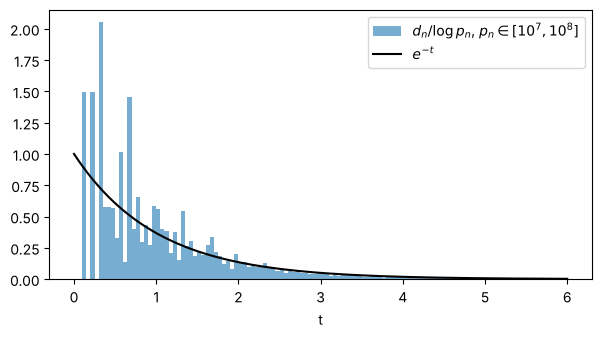

In [4]:
g = np.diff(P)
runmax = np.maximum.accumulate(g)
idx = np.nonzero(np.concatenate([[True], runmax[1:] > runmax[:-1]]))[0]
print(' p_n            gap   gap/log^2 p')
for i in idx[-12:]:
    p = int(P[i]); print('%12d %6d   %.3f' % (p, g[i], g[i] / math.log(p)**2))
sel = (P[:-1] >= 10**7)
t = (g[sel] / np.log(P[:-1][sel])).copy()
for d in (0.25, 0.5, 1.0):
    print('fraction of gaps below %.2f log p: %.4f   (exponential model %.4f)' % (d, np.mean(t < d), 1 - math.exp(-d)))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(t, bins=np.arange(0, 6, 0.05), density=True, alpha=0.6, label='$d_n/\\log p_n$, $p_n\\in[10^7,10^8]$')
u = np.linspace(0, 6, 300); ax.plot(u, np.exp(-u), 'k', label='$e^{-t}$')
ax.set_xlabel('t'); ax.legend(); plt.show()

The largest gap below $10^8$ is $220$, after $47326693$, and $\frac{220}{(\log p)^2}\approx0.70$; the records stay below $(\log p)^2$, in line with Cramér's model. The histogram has the exponential shape, with spikes: gaps are even, and multiples of $6$ are favoured, exactly as the singular series $\mathfrak S(h)$ says. About $15\%$ of the gaps are below $\frac14\log p$, a comfortable positive proportion as Theorem 2.4 guarantees, though fewer than the exponential model's $1-e^{-1/4}\approx22\%$. The reason is parity: here $\frac14\log p\approx4.4$, so only the gaps $2$ and $4$ count, while the continuous model spreads its mass over every real number below $4.4$. For $\delta=1$ the two agree to within two percent.

### P2.4
**How to find it.** Sieve $\frac{p-1}{p-2}$ multiplicatively over odd prime divisors, with a smallest-prime-factor table.

In [5]:
Hmax = 10**6
fac = np.ones(Hmax + 1)
for p in sympy.primerange(3, Hmax + 1):
    fac[p::p] *= (p - 1) / (p - 2)
S = 2 * C2 * fac; S[1::2] = 0; S[0] = 0
for e in range(2, 7):
    H = 10**e
    print('H=10^%d  average of S(h), h<=H: %.5f' % (e, S[1:H + 1].mean()))
L = Li(N, 2)
for h in (2, 6, 30, 210):
    cnt = int((s[:N + 1] & s[h:N + 1 + h]).sum())
    print('h=%3d  S(h)=%.4f  count %8d  ratio %.4f' % (h, S[h], cnt, cnt / (S[h] * L)))
phi = np.arange(Hmax + 1, dtype=float)
for p in sympy.primerange(2, Hmax + 1):
    phi[p::p] *= 1 - 1 / p
avg = (np.arange(1, Hmax + 1) / phi[1:]).mean()
print('average of n/phi(n), n <= 10^6: %.6f   zeta(2)zeta(3)/zeta(6) = %.6f' % (avg, float(sympy.zeta(2) * sympy.zeta(3) / sympy.zeta(6))))

H=10^2  average of S(h), h<=H: 0.97226
H=10^3  average of S(h), h<=H: 0.99608
H=10^4  average of S(h), h<=H: 0.99951
H=10^5  average of S(h), h<=H: 0.99994
H=10^6  average of S(h), h<=H: 0.99999
h=  2  S(h)=1.3203  count   440312  ratio 0.9999


h=  6  S(h)=2.6406  count   879908  ratio 0.9991
h= 30  S(h)=3.5209  count  1173934  ratio 0.9997
h=210  S(h)=4.2250  count  1409150  ratio 1.0000


average of n/phi(n), n <= 10^6: 1.943589   zeta(2)zeta(3)/zeta(6) = 1.943596


The average of $\mathfrak S(h)$ tends to $1$ (with an error of order $\frac{\log H}H$): on average a gap-pattern is exactly as likely as independent coin flips predict, and $h=6,30,210$ beat $h=2$ by the factors $2$, $2\cdot\frac43$ and $2\cdot\frac43\cdot\frac65$ (one factor $\frac{p-1}{p-2}$ for each odd prime dividing $h$), which the counts confirm to within $0.1\%$. The average of $\frac n{\varphi(n)}$ agrees with $\frac{\zeta(2)\zeta(3)}{\zeta(6)}\approx1.943596$ to five digits, as Exercise 2.6 predicts.

### P2.5
**How to find it.** The pattern of integers coprime to $m$ is periodic, so one period suffices. For the construction, follow the proof of Theorem 2.5: use the class $a_p=1$ for the primes $p\le z$ and $a_p=0$ for the primes in $(z,x/2]$, cover the survivors in $[1,x]$ with the primes in $(x/2,x]$, one each, and solve $n\equiv-a_p\pmod p$.

In [6]:
def longest_run(m):
    best = cur = 0; start = 0
    for n in range(1, m + 1):
        if math.gcd(n, m) > 1:
            cur += 1
            if cur > best: best, start = cur, n - cur + 1
        else:
            cur = 0
    return best, start
for m in (6, 30, 210, 2310, 30030):
    b, st = longest_run(m); print('m=%5d  longest run %2d  starting at %d' % (m, b, st))

x, z = 30, 2
small = list(sympy.primerange(2, z + 1))
mid = list(sympy.primerange(z + 1, x // 2 + 1))
big = list(sympy.primerange(x // 2 + 1, x + 1))
y = x
# a_p = the class modulo p we use; j in [1, y] is covered when j = a_p (mod p) for some p
a = {p: 1 for p in small}
for p in mid: a[p] = 0
covered = lambda j: any((j - a[p]) % p == 0 for p in a)
left = [j for j in range(1, y + 1) if not covered(j)]
print('survivors of Step 1:', left, ' big primes available:', big)
assert len(left) <= len(big)
for p, j in zip(big, left):
    a[p] = j % p
for p in big[len(left):]:
    a[p] = 0
assert all(covered(j) for j in range(1, y + 1))
n, M = crt(list(a), [(-a[p]) % p for p in a])   # n = -a_p (mod p), so p | n + j when j = a_p
print('n =', n, ' modulus', M)
print('all of n+1..n+30 composite:', all(not sympy.isprime(n + j) for j in range(1, y + 1)))

m=    6  longest run  3  starting at 2
m=   30  longest run  5  starting at 2
m=  210  longest run  9  starting at 2
m= 2310  longest run 13  starting at 114
m=30030  longest run 21  starting at 9440
survivors of Step 1: [2, 4, 8, 16]  big primes available: [17, 19, 23, 29]
n = 4450491045  modulus 6469693230
all of n+1..n+30 composite: True


The runs have lengths $3,5,9,13,21$, so Jacobsthal's $j(m)$ is $4,6,10,14,22$. For $x=30$, with $z=2$ (the class $1$ modulo $2$ and the class $0$ modulo $3,5,7,11,13$, as in Step 1 of the proof), only the four positions $2,4,8,16$ survive, just few enough to be covered by the four primes $17,19,23,29$, one each. (With $z=3$ six positions would survive, too many: at this tiny size the choice of $z$ matters.) The Chinese remainder theorem produces an $n$ with $n+1,\dots,n+30$ all composite. It is huge (it lives modulo the primorial $30\#$), while the first run of $30$ consecutive composites starts at $1328$, after the prime $1327$: the construction is a proof of existence, not a search tool.